# 4. Benchmark: the airline fare-class method (EMSR-b)

Airlines rarely set a free price each day. They sell a ladder of **nested booking classes** (fare buckets) and decide which classes are open. Each class has a **protection level**: seats held back for the classes above it. The classic way to set protection levels is **EMSR-b** (Belobaba). This notebook adds it to the same simulator and asks: **how does the dynamic program from [`02_pricing_engine.ipynb`](02_pricing_engine.ipynb) compare with what airlines actually use?**

### How the fare-class policy works here

- **Booking classes:** the six fare levels, ₹935 to ₹1,430. Classes are nested, so a seat available in a cheap class is also available in every dearer one.
- **Passengers buy the cheapest open class.** The simulator's demand already behaves this way: bookings depend on the lowest fare on offer.
- **Protection levels:** EMSR-b pools the classes above each cut-off and applies Littlewood's rule. It keeps protecting seats while P(demand from the higher classes ≥ seats protected) ≥ the lower fare ÷ their average fare.
- **Re-optimization:** protection levels are re-solved for the demand still to come and the seats left. This happens either every day or at 8 airline-style data collection points (60, 45, 30, 21, 14, 7, 3 and 1 days out, plus departure day).

### Two versions

| Version | Class demand | Class value |
|---|---|---|
| **Textbook EMSR-b** | Passengers whose willingness to pay falls between this fare and the next higher one; classes assumed independent | The class fare |
| **Fare-adjusted EMSR-b** | Same | **Adjusted fare**: the extra revenue from opening the class, (fare × Q − fare above × Q above) ÷ (Q − Q above), where Q is demand when that class is the cheapest open. Classes with an adjusted fare ≤ 0 stay closed. |

The textbook version assumes a passenger who would pay ₹1,430 still buys ₹1,430 when ₹935 is open. With price-sensitive passengers that isn't true: they **buy down**. Fare adjustment (the marginal-revenue transformation, Fiig et al. 2010) is the industry's correction for this.

The policy is `EMSRb` in [`src/pricing_sim.py`](../src/pricing_sim.py), with tests in [`tests/test_pricing_sim.py`](../tests/test_pricing_sim.py).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

sys.path.insert(0, "../src")
from data_loader import load_bookings, daily_totals
from pricing_sim import (Market, BookingState, FixedFare, ForecastOptimizer, EMSRb, BASE_FARE, CAPACITY, HORIZON,
                         FARE_LEVELS, booking_curve_from_bookings, demand_levels, forecast_levels, evaluate, summarize)

pd.set_option("display.precision", 1)
COLUMNS = ["revenue", "load_factor_%", "avg_fare", "uplift_vs_fixed_%", "uplift_ci_%", "passengers_vs_fixed_%"]
DCP = EMSRb.DATA_COLLECTION_POINTS

## 1. Same calibration and test departures as notebook 2

In [2]:
bookings = load_bookings(cls="3A")
booking_curve = booking_curve_from_bookings(bookings[pd.to_datetime(bookings.journey_date) >= "2025-03-01"])
daily = daily_totals(bookings)
train = daily[daily.journey_date < "2024-08-01"]
test = daily[daily.journey_date >= "2024-08-01"]
test_levels, test_forecasts = demand_levels(test, train), forecast_levels(test, train)
print(f"{len(test_levels)} test departures, Aug 2024 - Jul 2025; forecast error {100 * np.mean(np.abs(test_levels.values / test_forecasts.values - 1)):.1f}%")

365 test departures, Aug 2024 - Jul 2025; forecast error 6.9%


## 2. What each method would do

Each panel shows the fare offered for every combination of days before departure and seats left, for an average departure in the *price-sensitive, oversubscribed* scenario. For the fare-class methods, the fare offered is the cheapest open class.

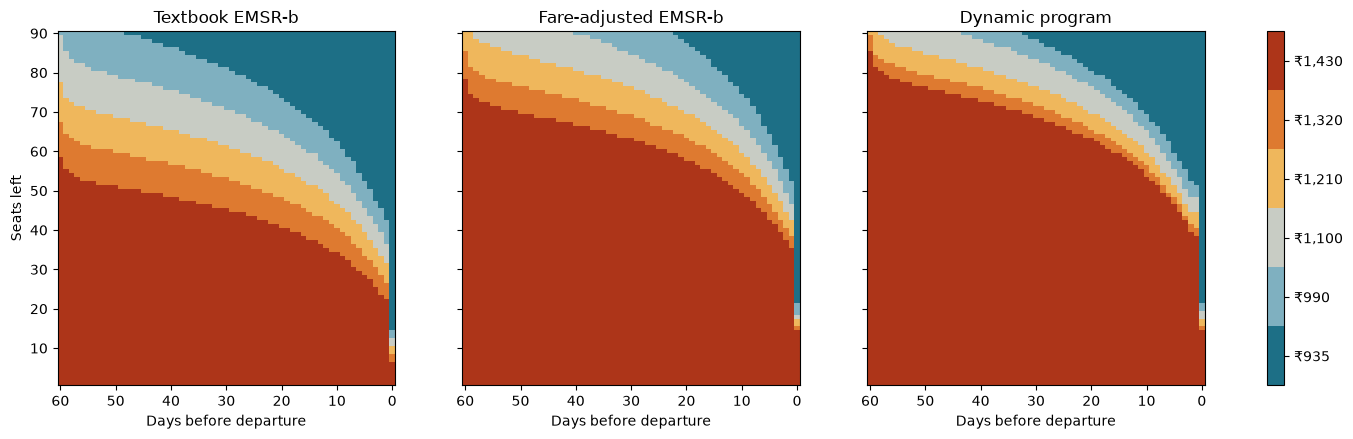

Textbook EMSR-b, booking opens: protect 58, 67, 77, 89, 102 seats for the classes above ₹1,320, ₹1,210, ₹1,100, ₹990, ₹935
Fare-adjusted EMSR-b, booking opens: protect 78, 85, 94, 105, 118 seats for the classes above ₹1,320, ₹1,210, ₹1,100, ₹990, ₹935


In [3]:
market = Market(booking_curve, elasticity=1.2, demand_at_base=95)
methods = {"Textbook EMSR-b": EMSRb(), "Fare-adjusted EMSR-b": EMSRb(fare_adjustment=True),
           "Dynamic program": ForecastOptimizer()}
seats = np.arange(1, CAPACITY + 1)
cmap = ListedColormap(["#1d6f86", "#7fb0c0", "#c8ccc4", "#efb75c", "#de7a30", "#ad3519"])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, (label, policy) in zip(axes, methods.items()):
    grid = np.array([policy.choose(BookingState(d, seats, np.zeros(CAPACITY, int), np.zeros(CAPACITY), 1.0), market)
                     for d in range(HORIZON, -1, -1)]).T
    im = ax.imshow(grid, origin="lower", aspect="auto", cmap=cmap, vmin=-0.5, vmax=5.5,
                   extent=[HORIZON + 0.5, -0.5, 0.5, CAPACITY + 0.5])
    ax.set(title=label, xlabel="Days before departure")
axes[0].set_ylabel("Seats left")
cbar = fig.colorbar(im, ax=axes, ticks=range(6), fraction=0.025)
cbar.ax.set_yticklabels([f"₹{f * BASE_FARE:,.0f}" for f in FARE_LEVELS])
plt.show()

for label, policy in methods.items():
    if isinstance(policy, EMSRb):
        order, y, n_open = policy.classes(market, 1.0, HORIZON)
        print(f"{label}, booking opens: protect {', '.join(f'{int(v)}' for v in y)} seats for the classes above "
              + ", ".join(f"₹{FARE_LEVELS[i] * BASE_FARE:,.0f}" for i in order[1:n_open]))

## 3. Head-to-head on the 365 unseen departures

Same four scenarios, same random passengers for every method (20 booking windows per departure), and the same calendar forecast.

In [4]:
SCENARIOS = {"Price-sensitive, spare seats": (1.2, 75), "Price-sensitive, oversubscribed": (1.2, 95),
             "Less price-sensitive, spare seats": (0.8, 75), "Less price-sensitive, oversubscribed": (0.8, 95)}
ORDER = ["EMSR-b (textbook)", "EMSR-b, fare-adjusted, 8 re-optimizations", "EMSR-b, fare-adjusted, daily",
         "Forecast + optimizer", "Perfect-information ceiling"]
summaries = {}
for label, (elasticity, demand) in SCENARIOS.items():
    market = Market(booking_curve, elasticity=elasticity, demand_at_base=demand)
    policies = [FixedFare(), EMSRb(),
                EMSRb(fare_adjustment=True, reoptimize_at=DCP, name="EMSR-b, fare-adjusted, 8 re-optimizations"),
                EMSRb(fare_adjustment=True, name="EMSR-b, fare-adjusted, daily"), ForecastOptimizer()]
    summaries[label] = summarize(evaluate(policies, market, test_levels, test_forecasts, runs_per_departure=20))
    print(f"\n=== {label} (elasticity {elasticity}, {demand} bookings per 90 seats at base fare) ===")
    display(summaries[label][COLUMNS])


=== Price-sensitive, spare seats (elasticity 1.2, 75 bookings per 90 seats at base fare) ===


,revenue,load_factor_%,avg_fare,uplift_vs_fixed_%,uplift_ci_%,passengers_vs_fixed_%
policy,,,,,,
EMSR-b (textbook),81353.5,94.2,959.7,-0.2,0.1,14.4
Fixed fare (today),81513.3,82.3,1100.0,0.0,0.0,0.0
"EMSR-b, fare-adjusted, 8 re-optimizations",83019.3,91.0,1013.2,1.8,0.1,10.6
"EMSR-b, fare-adjusted, daily",83086.0,91.7,1007.2,1.9,0.1,11.3
Forecast + optimizer,83170.6,91.8,1006.2,2.0,0.1,11.5
Perfect-information ceiling,83265.0,91.6,1010.6,2.1,0.1,11.2



=== Price-sensitive, oversubscribed (elasticity 1.2, 95 bookings per 90 seats at base fare) ===


,revenue,load_factor_%,avg_fare,uplift_vs_fixed_%,uplift_ci_%,passengers_vs_fixed_%
policy,,,,,,
Fixed fare (today),95110.2,96.1,1100.0,0.0,0.0,0.0
EMSR-b (textbook),96735.7,99.0,1085.5,1.7,0.1,3.1
"EMSR-b, fare-adjusted, daily",101176.8,95.0,1183.0,6.4,0.2,-1.1
"EMSR-b, fare-adjusted, 8 re-optimizations",101201.2,94.7,1187.8,6.4,0.2,-1.5
Forecast + optimizer,101337.2,94.3,1194.3,6.5,0.2,-1.9
Perfect-information ceiling,101568.3,94.7,1191.9,6.8,0.2,-1.4



=== Less price-sensitive, spare seats (elasticity 0.8, 75 bookings per 90 seats at base fare) ===


,revenue,load_factor_%,avg_fare,uplift_vs_fixed_%,uplift_ci_%,passengers_vs_fixed_%
policy,,,,,,
EMSR-b (textbook),77955.5,90.9,952.8,-4.4,0.1,10.4
Fixed fare (today),81513.3,82.3,1100.0,0.0,0.0,0.0
"EMSR-b, fare-adjusted, 8 re-optimizations",86741.1,67.4,1430.0,6.4,0.1,-18.1
"EMSR-b, fare-adjusted, daily",86741.1,67.4,1430.0,6.4,0.1,-18.1
Forecast + optimizer,86741.1,67.4,1430.0,6.4,0.1,-18.1
Perfect-information ceiling,86741.1,67.4,1430.0,6.4,0.1,-18.1



=== Less price-sensitive, oversubscribed (elasticity 0.8, 95 bookings per 90 seats at base fare) ===


,revenue,load_factor_%,avg_fare,uplift_vs_fixed_%,uplift_ci_%,passengers_vs_fixed_%
policy,,,,,,
Fixed fare (today),95110.2,96.1,1100.0,0.0,0.0,0.0
EMSR-b (textbook),96788.5,98.5,1091.9,1.8,0.2,2.5
"EMSR-b, fare-adjusted, 8 re-optimizations",108401.2,84.2,1430.0,14.0,0.2,-12.3
"EMSR-b, fare-adjusted, daily",108401.2,84.2,1430.0,14.0,0.2,-12.3
Forecast + optimizer,108401.2,84.2,1430.0,14.0,0.2,-12.3
Perfect-information ceiling,108401.2,84.2,1430.0,14.0,0.2,-12.3


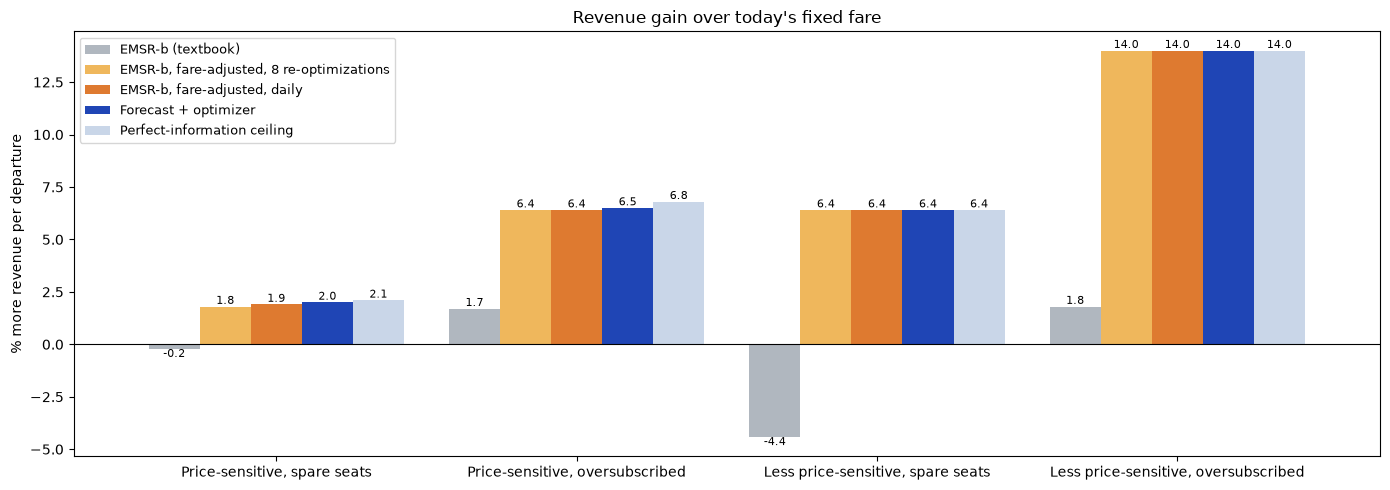

Share of the achievable gain captured (%):


,"Price-sensitive, spare seats","Price-sensitive, oversubscribed","Less price-sensitive, spare seats","Less price-sensitive, oversubscribed"
policy,,,,
EMSR-b (textbook),-10.0,25.0,-69.0,13.0
"EMSR-b, fare-adjusted, 8 re-optimizations",86.0,94.0,100.0,100.0
"EMSR-b, fare-adjusted, daily",90.0,94.0,100.0,100.0
Forecast + optimizer,95.0,96.0,100.0,100.0


Passengers vs fixed fare (%):


,"Price-sensitive, spare seats","Price-sensitive, oversubscribed","Less price-sensitive, spare seats","Less price-sensitive, oversubscribed"
policy,,,,
EMSR-b (textbook),14.4,3.1,10.4,2.5
"EMSR-b, fare-adjusted, 8 re-optimizations",10.6,-1.5,-18.1,-12.3
"EMSR-b, fare-adjusted, daily",11.3,-1.1,-18.1,-12.3
Forecast + optimizer,11.5,-1.9,-18.1,-12.3
Perfect-information ceiling,11.2,-1.4,-18.1,-12.3


In [5]:
uplift = pd.DataFrame({k: s["uplift_vs_fixed_%"] for k, s in summaries.items()}).loc[ORDER]
pax = pd.DataFrame({k: s["passengers_vs_fixed_%"] for k, s in summaries.items()}).loc[ORDER]
ax = uplift.T.plot.bar(figsize=(14, 5), width=0.85, rot=0, color=["#b0b7bf", "#efb75c", "#de7a30", "#1f45b5", "#c9d6e8"])
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Revenue gain over today's fixed fare", ylabel="% more revenue per departure")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=8)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

gap = uplift.loc["Perfect-information ceiling"]
captured = (100 * uplift.div(gap, axis=1)).round(0).loc[ORDER[:-1]]
print("Share of the achievable gain captured (%):")
display(captured)
print("Passengers vs fixed fare (%):")
display(pax.round(1))

## 4. Why the textbook version loses money

Textbook EMSR-b sees plenty of seats and plenty of "low-fare demand", so it opens the cheap classes early. But the passengers it planned to sell ₹1,320 and ₹1,430 seats to also see ₹935 on offer, and they buy that. The protection levels were right for the demand it *assumed*; the revenue is wrong because the demand *buys down*.

The table compares the average fare paid and the share of passengers who paid the lowest fare.

In [6]:
rows = []
for label, s in summaries.items():
    for name in ["Fixed fare (today)", "EMSR-b (textbook)", "EMSR-b, fare-adjusted, daily", "Forecast + optimizer"]:
        rows.append({"scenario": label, "method": name, "avg fare paid (₹)": s.loc[name, "avg_fare"],
                     "load factor %": s.loc[name, "load_factor_%"], "revenue vs fixed %": s.loc[name, "uplift_vs_fixed_%"]})
display(pd.DataFrame(rows).set_index(["scenario", "method"]))

avg fare paid (₹)  \
scenario                             method                                            
Price-sensitive, spare seats         Fixed fare (today)                       1100.0   
                                     EMSR-b (textbook)                         959.7   
                                     EMSR-b, fare-adjusted, daily             1007.2   
                                     Forecast + optimizer                     1006.2   
Price-sensitive, oversubscribed      Fixed fare (today)                       1100.0   
                                     EMSR-b (textbook)                        1085.5   
                                     EMSR-b, fare-adjusted, daily             1183.0   
                                     Forecast + optimizer                     1194.3   
Less price-sensitive, spare seats    Fixed fare (today)                       1100.0   
                                     EMSR-b (textbook)                         952.8   
                                     EMSR-b, fare-adjusted, daily             1430.0   
                                     Forecast + optimizer                     1430.0   
Less price-sensitive, oversubscribed Fixed fare (today)                       1100.0   
                                     EMSR-b (textbook)                        1091.9   
                                     EMSR-b, fare-adjusted, daily             1430.0   
                                     Forecast + optimizer                     1430.0   

                                                                   load factor %  \
scenario                             method                                        
Price-sensitive, spare seats         Fixed fare (today)                     82.3   
                                     EMSR-b (textbook)                      94.2   
                                     EMSR-b, fare-adjusted, daily           91.7   
                                     Forecast + optimizer                   91.8   
Price-sensitive, oversubscribed      Fixed fare (today)                     96.1   
                                     EMSR-b (textbook)                      99.0   
                                     EMSR-b, fare-adjusted, daily           95.0   
                                     Forecast + optimizer                   94.3   
Less price-sensitive, spare seats    Fixed fare (today)                     82.3   
                                     EMSR-b (textbook)                      90.9   
                                     EMSR-b, fare-adjusted, daily           67.4   
                                     Forecast + optimizer                   67.4   
Less price-sensitive, oversubscribed Fixed fare (today)                     96.1   
                                     EMSR-b (textbook)                      98.5   
                                     EMSR-b, fare-adjusted, daily           84.2   
                                     Forecast + optimizer                   84.2   

                                                                   revenue vs fixed %  
scenario                             method                                            
Price-sensitive, spare seats         Fixed fare (today)                           0.0  
                                     EMSR-b (textbook)                           -0.2  
                                     EMSR-b, fare-adjusted, daily                 1.9  
                                     Forecast + optimizer                         2.0  
Price-sensitive, oversubscribed      Fixed fare (today)                           0.0  
                                     EMSR-b (textbook)                            1.7  
                                     EMSR-b, fare-adjusted, daily                 6.4  
                                     Forecast + optimizer                         6.5  
Less price-sensitive, spare seats    Fixed fare (today)                           0.0  
 

## Takeaways

| Scenario | Textbook EMSR-b | Fare-adjusted EMSR-b (8 re-optimizations) | Fare-adjusted EMSR-b (daily) | Dynamic program | Ceiling |
|---|---|---|---|---|---|
| Price-sensitive, spare seats | **−0.2%** | +1.8% | +1.9% | +2.0% | +2.1% |
| Price-sensitive, oversubscribed | +1.7% | +6.4% | +6.4% | +6.5% | +6.8% |
| Less price-sensitive, spare seats | **−4.4%** | +6.4% | +6.4% | +6.4% | +6.4% |
| Less price-sensitive, oversubscribed | +1.8% | +14.0% | +14.0% | +14.0% | +14.0% |

- **Textbook EMSR-b can lose money against a fixed fare** (−4.4% and −0.2%), and captures at most a quarter of the achievable gain. It protects seats correctly for the demand it assumes, but opens cheap classes that passengers who would pay more simply buy down into. It fills more seats (+3% to +14% passengers) at a much lower average fare.
- **Fare-adjusted EMSR-b recovers almost everything:** 86–100% of the achievable gain, within 0.2 points of the dynamic program. Once each class is valued by the marginal revenue it adds, the fare-class method and the dynamic program draw almost the same fare map.
- **Re-optimizing at 8 data collection points instead of daily costs at most 0.1 points.** Daily re-optimization isn't needed to get the benefit.
- **What this means:** the dynamic program doesn't beat industry practice by much; it agrees with *good* industry practice. Its advantages are that it handles buy-down by construction rather than through a correction, and that it extends directly to fairness terms (value per passenger) and to network bid prices. The textbook result is the reason airlines moved to fare adjustment as demand became more price-driven.
- **Not modelled here: spiral-down.** In practice, textbook EMSR-b also learns its class forecasts from its own bookings. Fewer high-class bookings lead to lower high-class forecasts, which lead to even less protection. This simulation gives it the correct class demand, so the real-world gap would be larger.